In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
gender_submission = pd.read_csv("gender_submission.csv")

print("Training dataset:", train.shape)
print("Test dataset:", test.shape)
print("Gender submission:", gender_submission.shape)

display(train.head())

Training dataset: (891, 12)
Test dataset: (418, 11)
Gender submission: (418, 2)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
train.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [4]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
train.describe(include='all')

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,B96 B98,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [6]:
train.Survived.value_counts()


Survived
0    549
1    342
Name: count, dtype: int64

TIP----Out of 891 passengers, 342 survived and 549 did not survive. The survival rate was approximately 38.4%, indicating that most passengers in the training dataset did not survive.

In [7]:
train.Sex.value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

point-- The dataset contains 577 male passenger & 314 female passengers.
 Therefore, the training dataset contains a higher proportion of male passengers.

In [9]:
train.Pclass.value_counts()

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

The passenger class distribution shows that 
491 passengers travelled in third class, 
216  in first class, and 
184 in second class. 
Third-class passengers form the largest group in the dataset, while second-class passengers form the smallest group.

In [11]:
train.Embarked.value_counts()

Embarked
S    644
C    168
Q     77
Name: count, dtype: int64

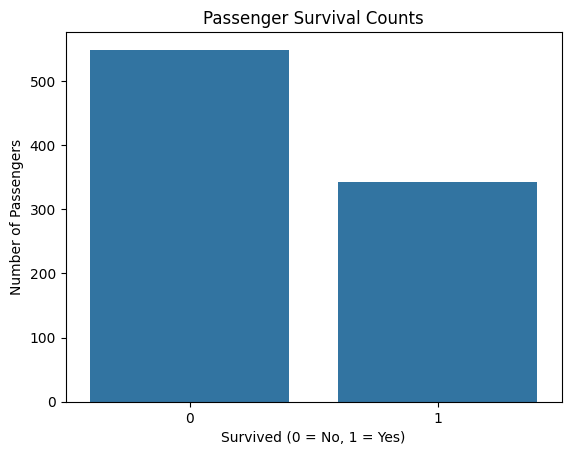

In [12]:
sns.countplot(data=train, x="Survived")

plt.title("Passenger Survival Counts")

plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

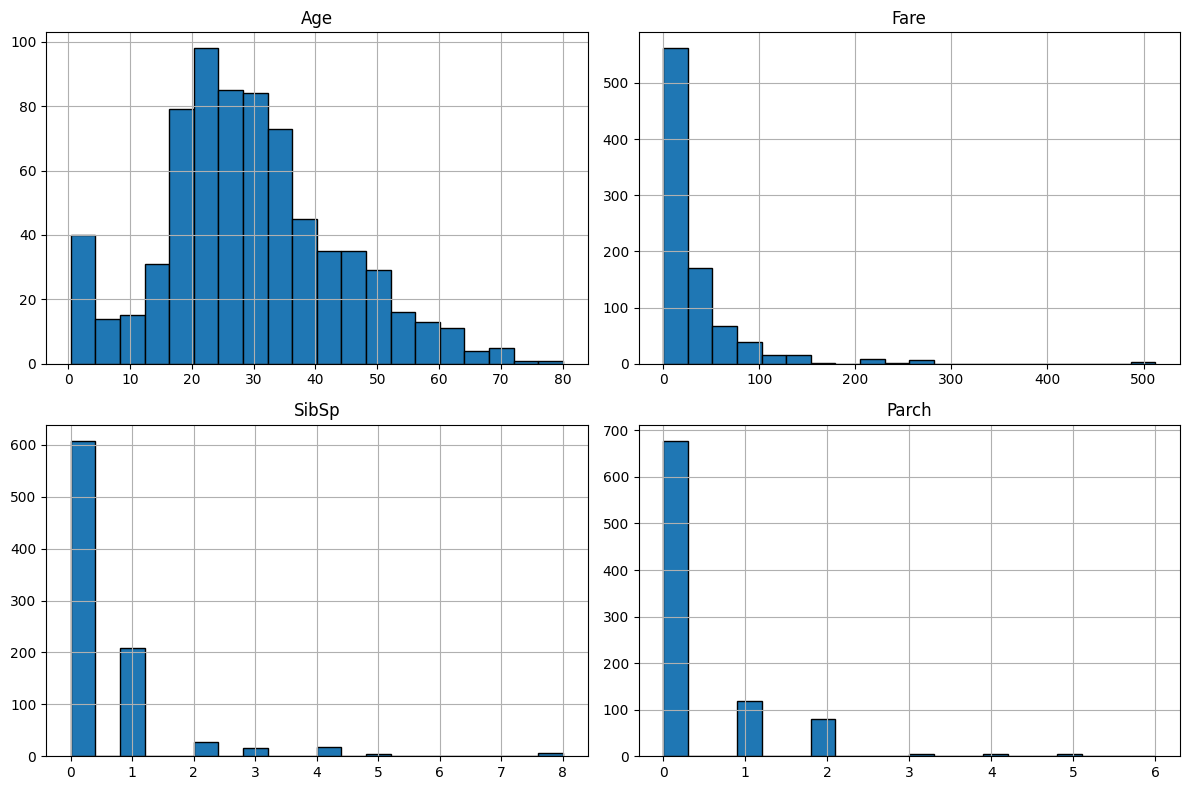

In [13]:
train[["Age", "Fare", "SibSp", "Parch"]].hist(
    bins=20,figsize=(12, 8),edgecolor="black")

plt.tight_layout()
plt.show()

Age: Most passengers were young or middle-aged adults, although age values are missing for some passengers./n


Fare: The distribution is right-skewed, with a small number of passengers paying much higher fares.


SibSp: Most passengers had no siblings or spouses aboard.


Parch: Most passengers had no parents or children aboard.


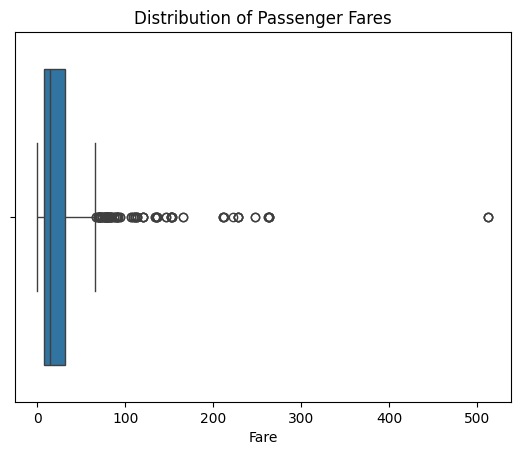

In [14]:
sns.boxplot(data=train, x="Fare")
plt.title("Distribution of Passenger Fares")
plt.xlabel("Fare")
plt.show()

The boxplot shows that passenger fares are positively skewed, with several points above the upper whisker representing potential outliers. Most passengers paid relatively low fares, while a small number paid considerably higher amounts.

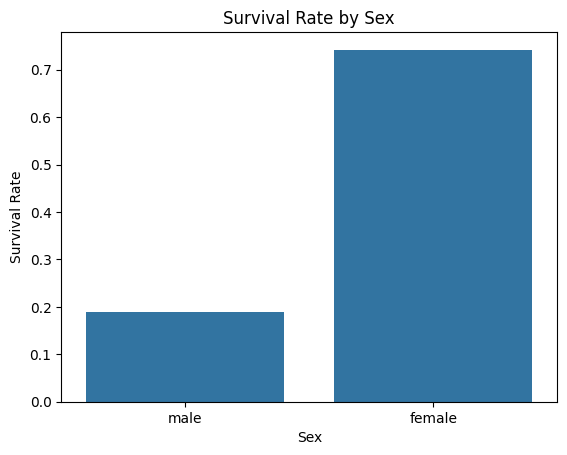

In [15]:
sns.barplot(data=train, x="Sex", y="Survived", errorbar=None)
plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")

plt.show()

The bar plot shows that female passengers had a considerably higher survival rate than male passengers. This suggests that sex was strongly associated with survival outcomes in the Titanic dataset.

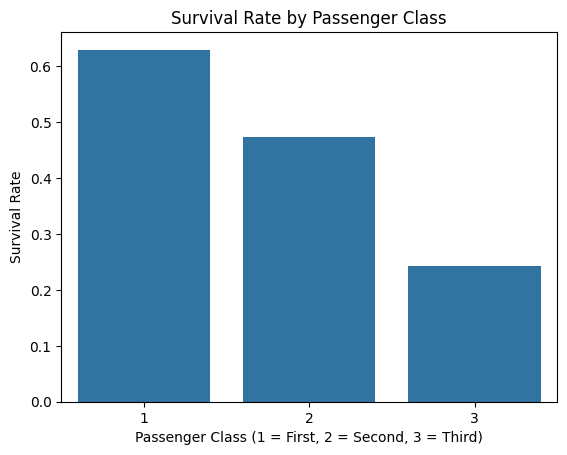

In [16]:
sns.barplot(data=train, x="Pclass", y="Survived", errorbar=None)


plt.title("Survival Rate by Passenger Class")

plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Survival Rate")

plt.show()

OBsevation::

The bar plot shows that first-class passengers had the highest survival rate, followed by second-class passengers, while third-class passengers had the lowest survival rate. This indicates an association between passenger class and survival outcomes. 

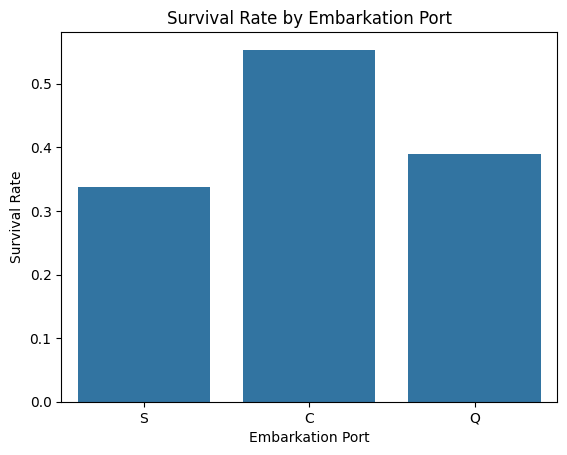

In [17]:
sns.barplot(data=train, x="Embarked", y="Survived", errorbar=None)

plt.title("Survival Rate by Embarkation Port")
plt.xlabel("Embarkation Port")
plt.ylabel("Survival Rate")

plt.show()

observation1:
The bar plot shows differences in survival rates among passengers who embarked at Southampton, Cherbourg, and Queenstown. Passengers who embarked at Cherbourg generally had a higher survival rate than those who embarked at Southampton or Queenstown. These differences may be associated with passenger class and other characteristics.

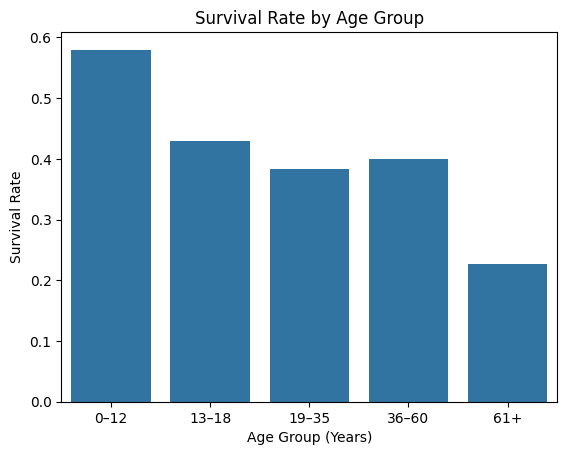

In [18]:

train["AgeGroup"] = pd.cut(
    train["Age"],
    bins=[0, 12, 18, 35, 60, 100],
    labels=["0–12", "13–18", "19–35", "36–60", "61+"],
    include_lowest=True)
sns.barplot(data=train, x="AgeGroup", y="Survived", errorbar=None)

plt.title("Survival Rate by Age Group")
plt.xlabel("Age Group (Years)")
plt.ylabel("Survival Rate")
plt.show()



1 Survival rates varied across age groups.
2 Children aged 0–12 generally had a relatively high survival rate.
3 Older passengers, particularly those aged 61 and above, generally had a lower survival rate.
4 The age pattern suggests that age may have been associated with survival, although age alone does not explain the outcome.
5 Some passengers had missing age values, so they are excluded from this chart.

Age is another useful variable for understanding passenger survival. 

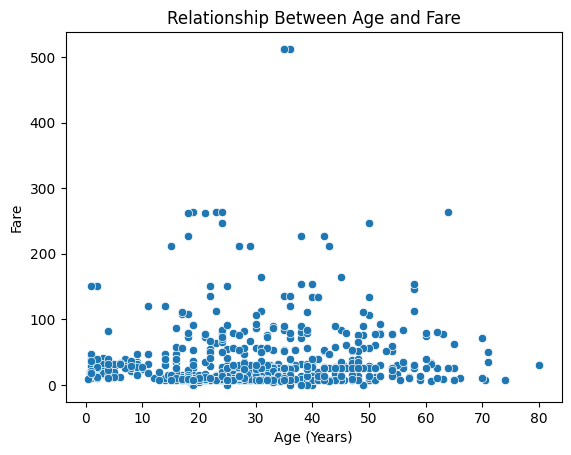

In [21]:

sns.scatterplot(data=train, x="Age", y="Fare")

plt.title("Relationship Between Age and Fare")
plt.xlabel("Age (Years)")
plt.ylabel("Fare")
plt.show()


1-Passengers of different ages paid a wide range of fares.
2-Most passengers are concentrated in the lower-fare range.

3-A few passengers paid substantially higher fares, creating points far above the main cluster.
Conclusion: Age alone does not appear to determine the fare paid.

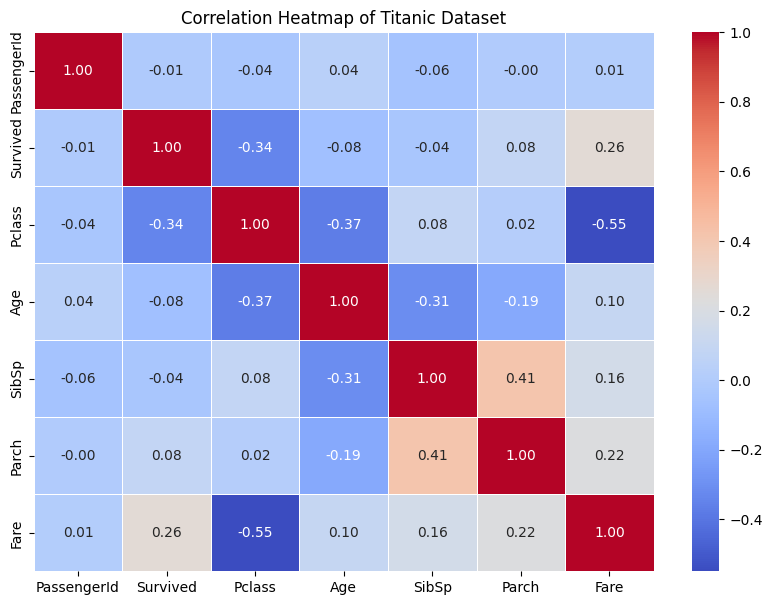

In [22]:

numeric_data = train.select_dtypes(include="number")
correlation = numeric_data.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5)

plt.title("Correlation Heatmap of Titanic Dataset")
plt.show()


Survived and Pclass: These variables have a negative correlation because a lower passenger-class number represents a higher class, and first-class passengers generally had better survival rates.


Survived and Fare: Fare has a positive correlation with survival that passengers who paid higher fares tended to have better survival outcomes.


SibSp and Parch: These variables describe siblings/spouses and parents/children aboard the ship. 



Age and Pclass: Age and passenger class may show a weak relationship in this dataset.

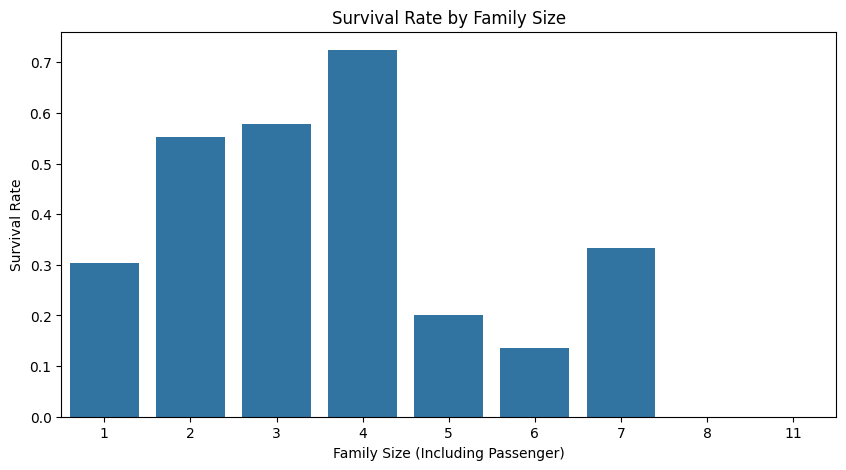

In [24]:

train["FamilySize"] = train["SibSp"] + train["Parch"] + 1
plt.figure(figsize=(10, 5))

sns.barplot(
    data=train,
    x="FamilySize",
    y="Survived",
    errorbar=None
)

plt.title("Survival Rate by Family Size")
plt.xlabel("Family Size (Including Passenger)")
plt.ylabel("Survival Rate")
plt.show()


Survival rates vary across different family sizes.


Passengers travelling alone may have had different survival outcomes from those travelling with family.


Very large family-size groups may show irregular rates because fewer passengers belong to these groups.


Family size alone cannot fully explain survival, and its relationship with sex and passenger class may also matter.